# LAB 05 — Sequence Models: RNN, LSTM and GRU. 

## 1. Imports and configuration

In [1]:
from pathlib import Path
import sys, json, csv, time
import numpy as np
import pandas as pd
import torch
from IPython.display import display

LAB_DIR = Path.cwd()
if not (LAB_DIR / "sequence_models.py").exists():
    LAB_DIR = LAB_DIR / "Lab05"
if not (LAB_DIR / "sequence_models.py").exists():
    raise FileNotFoundError("Run this notebook from the Lab05 folder or its parent.")
sys.path.insert(0, str(LAB_DIR))
from rnn_cell import SimpleRNNCell
from sequence_models import *

OUTPUT_DIR = LAB_DIR
RESULTS_PATH = OUTPUT_DIR / "results.csv"

## 2. Reproducibility / random seed

In [2]:
set_seed(SEED)
print({"seed": SEED, "validation_fraction": VALIDATION_FRACTION, "truncation_policy": TRUNCATION_POLICY,
       "epochs": EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE})

{'seed': 42, 'validation_fraction': 0.2, 'truncation_policy': 'keep_first', 'epochs': 3, 'batch_size': 128, 'learning_rate': 0.001}


## 3. Device configuration

In [3]:
DEVICE = get_device()
print({"device": str(DEVICE), "cuda_available": torch.cuda.is_available(),
       "cuda_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None})

{'device': 'cuda', 'cuda_available': True, 'cuda_name': 'NVIDIA GeForce RTX 3050 6GB Laptop GPU'}


## 4. Load IMDb dataset

In [4]:
DATA_AVAILABLE = False
DATASET_ERROR = None
SOURCE_TRAIN = SOURCE_TEST = None
DATASET_SOURCE = None
try:
    SOURCE_TRAIN, SOURCE_TEST, DATASET_SOURCE = load_imdb_dataset()
    DATA_AVAILABLE = True
    print({"source": DATASET_SOURCE, "train_samples": len(SOURCE_TRAIN), "test_samples": len(SOURCE_TEST)})
except DatasetRequiredError as exc:
    DATASET_ERROR = str(exc)
    print(DATASET_ERROR)

{'source': 'local CSV partitions: D:\\Study\\Semester 7\\NLP\\Lab05\\data', 'train_samples': 40000, 'test_samples': 10000}


## 5. Dataset inspection

In [5]:
dataset_summary = None
train_frame = validation_frame = test_frame = None
split_cleanup = {}
if DATA_AVAILABLE:
    dataset_summary = inspect_splits(SOURCE_TRAIN, SOURCE_TEST)
    train_frame, validation_frame, test_frame, split_cleanup = make_splits(SOURCE_TRAIN, SOURCE_TEST)
    dataset_summary["split_sizes_after_leakage_check"] = {
        "train": len(train_frame), "validation": len(validation_frame), "test": len(test_frame)}
    dataset_summary["duplicate_rows_removed_to_prevent_cross_split_leakage"] = split_cleanup
    display(pd.DataFrame([dataset_summary["length_statistics"]]))
    print({key: value for key, value in dataset_summary.items() if key not in {"lengths", "length_statistics"}})
else:
    print("[CHƯA CÓ KẾT QUẢ] Dataset inspection requires IMDb data.")

{'source_train_samples': 40000, 'source_test_samples': 10000, 'number_of_samples': 50000, 'number_of_classes': 2, 'class_distribution': {'negative': 25000, 'positive': 25000}, 'missing_texts': 0, 'missing_labels': 0, 'duplicate_documents': 421, 'duplicate_documents_train': 265, 'duplicate_documents_test': 15, 'cross_split_duplicates_before_cleaning': 141, 'split_sizes_after_leakage_check': {'train': 31879, 'validation': 7904, 'test': 10000}, 'duplicate_rows_removed_to_prevent_cross_split_leakage': {'removed_train_vs_test': 121, 'removed_validation_vs_test': 23, 'removed_validation_vs_train': 73, 'cross_split_duplicates_after_cleaning': 0}}


,number_of_samples,minimum_sequence_length,median_sequence_length,mean_sequence_length,maximum_sequence_length,P50,P75,P90,P95,P99
0,50000,6,176.0,234.96742,2493,176.0,285.25,458.1,599.0,918.0


## 6. Class distribution

In [6]:
if DATA_AVAILABLE:
    display(pd.DataFrame([{"label": "negative", "class_id": 0, "count": dataset_summary["class_distribution"]["negative"]},
                          {"label": "positive", "class_id": 1, "count": dataset_summary["class_distribution"]["positive"]}]))
else:
    print("[CHƯA CÓ KẾT QUẢ] Class distribution requires IMDb data.")

,label,class_id,count
0,negative,0,25000
1,positive,1,25000


## 7. Sequence length histogram

In [7]:
length_values = dataset_summary["lengths"] if DATA_AVAILABLE else []
HISTOGRAM_PATH = OUTPUT_DIR / "sequence_length_histogram.png"
plot_sequence_length_histogram(length_values, HISTOGRAM_PATH)
print(HISTOGRAM_PATH)

D:\Study\Semester 7\NLP\Lab05\sequence_length_histogram.png


## 8. Vocabulary

In [8]:
vocabulary = None
vocab_size = None
if DATA_AVAILABLE:
    vocabulary = Vocabulary.from_texts(train_frame["text"].tolist(), max_size=MAX_VOCAB_SIZE)
    vocab_size = len(vocabulary)
    assert vocabulary.token_to_id[PAD_TOKEN] == 0 and vocabulary.token_to_id[UNK_TOKEN] == 1
    print({"vocabulary_size": vocab_size, "built_from": "training split only", "PAD": 0, "UNK": 1})
else:
    print("[CHƯA CÓ KẾT QUẢ] Vocabulary requires the training split.")

{'vocabulary_size': 30000, 'built_from': 'training split only', 'PAD': 0, 'UNK': 1}


## 9. Tokenization

In [9]:
tokenization_example = "I never liked it — don't recommend it."
print({"text": tokenization_example, "tokens": tokenize_text(tokenization_example),
       "negations_preserved": all(word in tokenize_text(tokenization_example) for word in ("never", "don't"))})

{'text': "I never liked it — don't recommend it.", 'tokens': ['i', 'never', 'liked', 'it', "don't", 'recommend', 'it'], 'negations_preserved': True}


## 10. Padding / truncation

In [10]:
padding_report = {}
if DATA_AVAILABLE:
    original_train_lengths = [len(tokenize_text(text)) for text in train_frame["text"].tolist()]
    padding_report = {length: padding_statistics(original_train_lengths, length) for length in MAX_LENGTHS}
    display(pd.DataFrame.from_dict(padding_report, orient="index").rename_axis("max_length"))
else:
    print("[CHƯA CÓ KẾT QUẢ] Padding statistics require IMDb training data.")

,tokens_retained,documents_truncated,padded_tokens,average_original_length,average_effective_length
max_length,,,,,
50,0.212574,0.976474,6314,234.280498,49.801939
100,0.411170,0.882964,117026,234.280498,96.329057
200,0.683549,0.420684,1270629,234.280498,160.142131


## Analysis — Sequence Length Distribution

- **Tổng số mẫu:** 50.000
- **Phân bố lớp:** 25.000 tiêu cực / 25.000 tích cực (cân bằng)
- **Độ dài tối thiểu:** 6 token
- **Trung vị:** 176 token
- **Độ dài trung bình:** 234,97 token
- **Độ dài tối đa:** 2.493 token
- **P90:** 458,1 token
- **P95:** 599 token

Đây là số token trên toàn bộ 50.000 bài đánh giá. Nên chọn `max_length` theo tỷ lệ cắt bỏ chấp nhận được (ví dụ percentile P90/P95), sau đó kiểm tra chất lượng validation, thời gian và bộ nhớ; percentile chỉ hỗ trợ quyết định, không đảm bảo chất lượng mô hình tốt nhất. Trên tập train đã làm sạch, `max_length=50` giữ lại 21,26% tổng số token và cắt bỏ 78,74%; 97,65% tài liệu bị cắt. Với độ dài 100, 58,88% token bị cắt; với 200, tỷ lệ này là 31,65%. Tỷ lệ token bị mất có trọng số theo số token, khác với tỷ lệ tài liệu bị cắt.

**Padding** nối thêm token PAD vào chuỗi ngắn để các mẫu trong batch có cùng độ dài; thao tác này không xóa token của bài đánh giá. **Truncation** loại bỏ token vượt quá `max_length`. Notebook dùng `keep_first`, nên phần cuối của bài đánh giá dài bị loại bỏ.

### Biểu đồ phân bố độ dài chuỗi


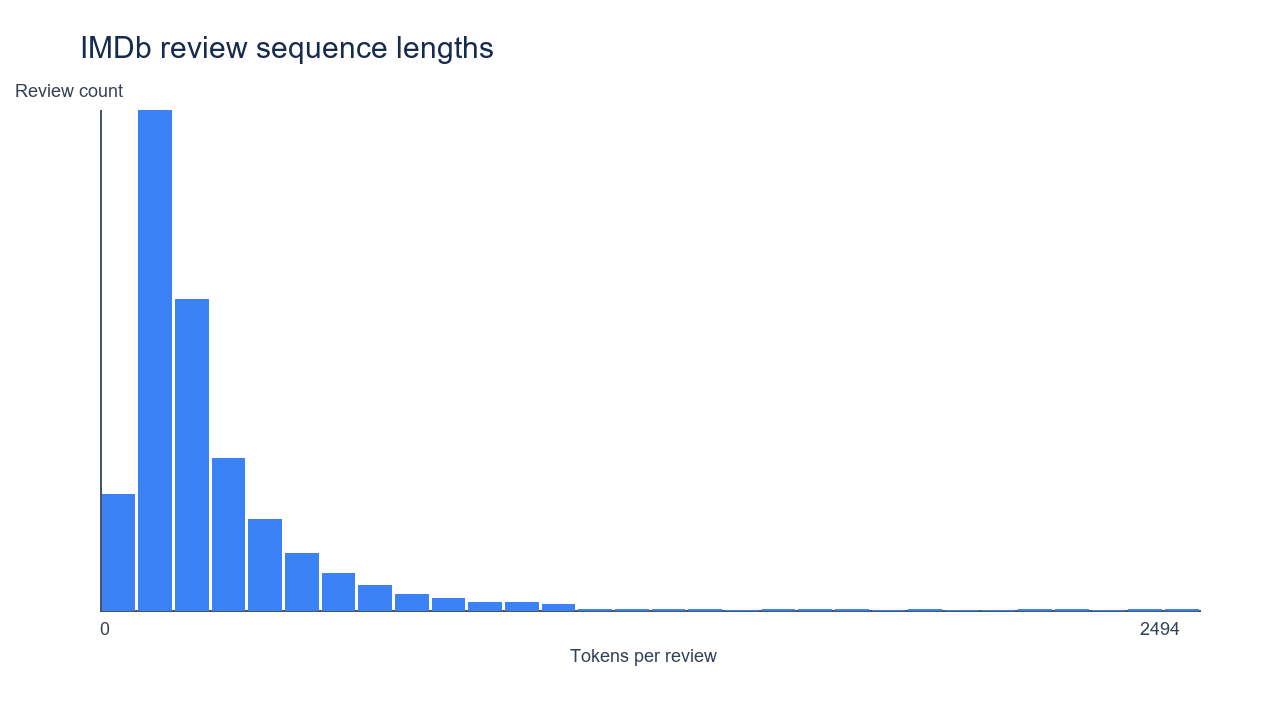

In [11]:
# LAB05_EMBEDDED_FIGURE: sequence_length_histogram.png
from pathlib import Path
from IPython.display import Image, display
_candidates = [Path('Lab05/sequence_length_histogram.png'), Path('sequence_length_histogram.png')]
_image_path = next((p for p in _candidates if p.exists()), None)
if _image_path is None:
    raise FileNotFoundError('sequence_length_histogram.png')
display(Image(filename=str(_image_path)))

## 11. SimpleRNNCell verification

In [12]:
manual_cell = SimpleRNNCell(input_size=2, hidden_size=2, dtype=torch.float64)
with torch.no_grad():
    manual_cell.weight_ih.copy_(torch.tensor([[0.5, 0.2], [0.1, 0.4]], dtype=torch.float64))
    manual_cell.weight_hh.copy_(torch.tensor([[0.3, 0.1], [0.2, 0.5]], dtype=torch.float64))
    manual_cell.bias_h.zero_()
x_t = torch.tensor([1.0, 0.0], dtype=torch.float64)
h_prev = torch.tensor([0.5, 0.2], dtype=torch.float64)
actual_hidden = manual_cell(x_t, h_prev)
expected_hidden = torch.tensor([0.584979883, 0.291312612], dtype=torch.float64)
torch.testing.assert_close(actual_hidden, expected_hidden, atol=1e-8, rtol=0.0)
reference_cell = torch.nn.RNNCell(2, 2, dtype=torch.float64)
with torch.no_grad():
    reference_cell.weight_ih.copy_(manual_cell.weight_ih)
    reference_cell.weight_hh.copy_(manual_cell.weight_hh)
    reference_cell.bias_ih.copy_(manual_cell.bias_h)
    reference_cell.bias_hh.zero_()
torch.testing.assert_close(actual_hidden, reference_cell(x_t, h_prev), atol=1e-12, rtol=0.0)
print({"W_xh_x": [0.5, 0.1], "W_hh_h": [0.17, 0.20], "a_t": [0.67, 0.30],
       "expected": expected_hidden.tolist(), "actual": actual_hidden.tolist(), "torch_RNNCell": "MATCH"})

{'W_xh_x': [0.5, 0.1], 'W_hh_h': [0.17, 0.2], 'a_t': [0.67, 0.3], 'expected': [0.584979883, 0.291312612], 'actual': [0.5849798828807288, 0.29131261245159096], 'torch_RNNCell': 'MATCH'}


## 12. TF-IDF + Logistic Regression baseline

In [13]:
result_rows = []
baseline_result = None
if DATA_AVAILABLE:
    baseline_result = run_tfidf_baseline(train_frame, validation_frame, test_frame)
    baseline_metadata = {"parameters": baseline_result["parameters"], "training_time": baseline_result["training_time"],
                         "vocabulary_size": baseline_result["vocabulary_size"], "epochs": 1}
    for split_name in ("validation", "test"):
        result_rows.append(metrics_result_row("baseline", "tfidf_logistic", split_name,
                             baseline_result[split_name], **baseline_metadata))
    display(pd.DataFrame([{key: baseline_result["test"][key] for key in ("accuracy", "precision", "recall", "f1")}]))
else:
    print("[CHƯA CÓ KẾT QUẢ] TF-IDF baseline requires the IMDb split.")

,accuracy,precision,recall,f1
0,0.8958,0.886071,0.9084,0.897097


## 13. PyTorch Dataset / DataLoader

In [14]:
models = {}
histories = {}
evaluations = {}
training_metadata = {}
def train_recurrent(model_type, max_length, experiment="model_comparison"):
    train_loader = make_loader(train_frame, vocabulary, max_length, shuffle=True, seed=SEED)
    validation_loader = make_loader(validation_frame, vocabulary, max_length)
    test_loader = make_loader(test_frame, vocabulary, max_length)
    set_seed(SEED)
    model, history, train_seconds, epochs_run = train_model(
        model_type, train_loader, validation_loader, vocab_size=vocab_size,
        max_length=max_length, device=DEVICE, epochs=EPOCHS, learning_rate=LEARNING_RATE,
        embedding_dim=EMBEDDING_DIM, hidden_dim=HIDDEN_DIM,
        checkpoint_dir=OUTPUT_DIR / "checkpoints")
    key = (model_type, max_length)
    models[key] = model
    histories[f"{model_type}_length_{max_length}"] = history
    evaluations[(model_type, max_length, "validation")] = evaluate(model, validation_loader, DEVICE)
    evaluations[(model_type, max_length, "test")] = evaluate(model, test_loader, DEVICE)
    memory_mb = torch.cuda.max_memory_allocated(DEVICE) / (1024 ** 2) if DEVICE.type == "cuda" else None
    stats = padding_statistics([len(tokenize_text(text)) for text in train_frame["text"]], max_length)
    metadata = {"max_length": max_length, "parameters": count_parameters(model), "training_time": train_seconds,
                "vocabulary_size": vocab_size, "embedding_dim": EMBEDDING_DIM, "hidden_dim": HIDDEN_DIM,
                "epochs": epochs_run, "memory_mb": memory_mb, **stats}
    training_metadata[key] = metadata
    for split_name in ("validation", "test"):
        result_rows.append(metrics_result_row(experiment, model_type, split_name,
                             evaluations[(model_type, max_length, split_name)],
                             **metadata, validation_loss=min(history["validation_loss"])))
    return model, history, evaluations[(model_type, max_length, "test")], metadata
if DATA_AVAILABLE:
    print({"train_loader_batches": len(make_loader(train_frame, vocabulary, BASE_MAX_LENGTH, shuffle=True)),
           "batch_size": BATCH_SIZE, "padding_index": PAD_INDEX})
else:
    print("[CHƯA CÓ KẾT QUẢ] DataLoader requires the IMDb training split.")

{'train_loader_batches': 250, 'batch_size': 128, 'padding_index': 0}


## 14. RNN classifier

In [15]:
if DATA_AVAILABLE:
    rnn_model, rnn_history, rnn_test, rnn_metadata = train_recurrent("rnn", BASE_MAX_LENGTH)
    print({"model": "rnn", **{key: rnn_test[key] for key in ("accuracy", "precision", "recall", "f1")}, **rnn_metadata})
else:
    print("[CHƯA CÓ KẾT QUẢ] RNN training requires IMDb data.")

{'model': 'rnn', 'accuracy': 0.5899, 'precision': 0.5608336716741101, 'recall': 0.8288, 'f1': 0.6689805472596658, 'max_length': 100, 'parameters': 1928385, 'training_time': 33.707558599999174, 'vocabulary_size': 30000, 'embedding_dim': 64, 'hidden_dim': 64, 'epochs': 3, 'memory_mb': 68.3115234375, 'tokens_retained': 0.4111697623713485, 'documents_truncated': 0.8829637065152608, 'padded_tokens': 117026, 'average_original_length': 234.28049813356756, 'average_effective_length': 96.32905674582014}


## Analysis — TF-IDF vs RNN

| Mô hình | Accuracy | Precision | Recall | F1 | Thời gian train |
|---|---:|---:|---:|---:|---:|
| TF-IDF + Logistic Regression | 0.8958 | 0.8861 | 0.9084 | 0.8971 | 5,89 s |
| RNN (`max_length=100`) | 0.5899 | 0.5608 | 0.8288 | 0.6690 | 33,71 s |

Trong lần chạy này, TF-IDF + LR có test F1 cao hơn (0,8971 so với 0,6690; chênh lệch 0,2281). TF-IDF biểu diễn trọng số token mà không giữ vị trí; RNN nhận token theo một chuỗi có thứ tự. So sánh metric này **không chứng minh** RNN đã học được thứ tự từ: thí nghiệm không xáo trộn hoặc đổi thứ tự trên cùng một tập bài đánh giá như một phép so sánh có kiểm soát.

## 15. LSTM classifier

In [16]:
if DATA_AVAILABLE:
    lstm_model, lstm_history, lstm_test, lstm_metadata = train_recurrent("lstm", BASE_MAX_LENGTH)
    print({"model": "lstm", **{key: lstm_test[key] for key in ("accuracy", "precision", "recall", "f1")}, **lstm_metadata})
else:
    print("[CHƯA CÓ KẾT QUẢ] LSTM training requires IMDb data.")

{'model': 'lstm', 'accuracy': 0.7583, 'precision': 0.7364085667215815, 'recall': 0.8046, 'f1': 0.7689955079805026, 'max_length': 100, 'parameters': 1953345, 'training_time': 38.44231519999448, 'vocabulary_size': 30000, 'embedding_dim': 64, 'hidden_dim': 64, 'epochs': 3, 'memory_mb': 103.65869140625, 'tokens_retained': 0.4111697623713485, 'documents_truncated': 0.8829637065152608, 'padded_tokens': 117026, 'average_original_length': 234.28049813356756, 'average_effective_length': 96.32905674582014}


## 16. GRU classifier

In [17]:
if DATA_AVAILABLE:
    gru_model, gru_history, gru_test, gru_metadata = train_recurrent("gru", BASE_MAX_LENGTH)
    print({"model": "gru", **{key: gru_test[key] for key in ("accuracy", "precision", "recall", "f1")}, **gru_metadata})
else:
    print("[CHƯA CÓ KẾT QUẢ] GRU training requires IMDb data.")

{'model': 'gru', 'accuracy': 0.7975, 'precision': 0.7524181231970134, 'recall': 0.8868, 'f1': 0.8141007986780501, 'max_length': 100, 'parameters': 1945025, 'training_time': 36.419441800011555, 'vocabulary_size': 30000, 'embedding_dim': 64, 'hidden_dim': 64, 'epochs': 3, 'memory_mb': 117.76318359375, 'tokens_retained': 0.4111697623713485, 'documents_truncated': 0.8829637065152608, 'padded_tokens': 117026, 'average_original_length': 234.28049813356756, 'average_effective_length': 96.32905674582014}


## 17. Model comparison

In [18]:
if DATA_AVAILABLE:
    comparison = pd.DataFrame([row for row in result_rows if row["split"] == "test" and row["experiment"] in {"baseline", "model_comparison"}])
    display(comparison[["model", "parameters", "training_time", "accuracy", "precision", "recall", "f1", "vocabulary_size", "max_length", "epochs"]])
else:
    print("[CHƯA CÓ KẾT QUẢ] Model comparison requires completed baseline and recurrent runs.")

,model,parameters,training_time,accuracy,precision,recall,f1,vocabulary_size,max_length,epochs
0,tfidf_logistic,50001,5.893100,0.8958,0.886071,0.9084,0.897097,50000,NaN,1
1,rnn,1928385,33.707559,0.5899,0.560834,0.8288,0.668981,30000,100.0,3
2,lstm,1953345,38.442315,0.7583,0.736409,0.8046,0.768996,30000,100.0,3
3,gru,1945025,36.419442,0.7975,0.752418,0.8868,0.814101,30000,100.0,3


## Analysis — RNN, LSTM and GRU

| Mô hình | Số tham số | Thời gian train | Bộ nhớ CUDA đỉnh | Validation F1 | Test accuracy | Test precision | Test recall | Test F1 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| RNN | 1.928.385 | 33,71 s | 68,31 MB | 0.6723 | 0.5899 | 0.5608 | 0.8288 | 0.6690 |
| LSTM | 1.953.345 | 38,44 s | 103,66 MB | 0.7668 | 0.7583 | 0.7364 | 0.8046 | 0.7690 |
| GRU | 1.945.025 | 36,42 s | 117,76 MB | 0.8130 | 0.7975 | 0.7524 | 0.8868 | 0.8141 |

GRU có validation/test F1 cao nhất (0,8130 / 0,8141). Trong ba mô hình hồi quy, RNN train nhanh nhất (33,71 s); xét tất cả mô hình, TF-IDF + LR nhanh nhất với 5,89 s. LSTM có nhiều tham số nhất (1.953.345). Trong lần chạy này, LSTM có test F1 cao hơn RNN (0,7690 so với 0,6690), nhưng một lần chạy không xác lập thứ hạng tổng quát và cũng không đo trực tiếp khả năng giữ phụ thuộc dài hạn. Với cấu hình này, GRU là lựa chọn cân bằng hợp lý giữa F1 và thời gian: F1 cao nhất trong nhóm hồi quy và train nhanh hơn LSTM, nhưng bộ nhớ đo được (117,76 MB) lại cao nhất trong ba mô hình.

## 18. Sequence length experiment

In [19]:
if DATA_AVAILABLE:
    length_results = []
    for length in (50, 200):
        _, _, _, _ = train_recurrent("gru", length, experiment="sequence_length")
    length_results = [row for row in result_rows if row["experiment"] == "sequence_length" and row["split"] == "test"]
    length_results += [row for row in result_rows if row["experiment"] == "model_comparison" and row["model"] == "gru" and row["split"] == "test"]
    length_100_row = next(row for row in length_results if row["model"] == "gru" and row["max_length"] == 100)
    result_rows.append({**length_100_row, "experiment": "sequence_length"})
    display(pd.DataFrame(length_results)[["max_length", "tokens_retained", "documents_truncated", "training_time", "memory_mb", "validation_loss", "accuracy", "precision", "recall", "f1"]].sort_values("max_length"))
else:
    length_results = []
    print("[CHƯA CÓ KẾT QUẢ] Sequence length experiment requires IMDb data.")
SEQUENCE_LENGTH_PATH = OUTPUT_DIR / "sequence_length_experiment.png"
plot_sequence_length_results(length_results, SEQUENCE_LENGTH_PATH)
print(SEQUENCE_LENGTH_PATH)

D:\Study\Semester 7\NLP\Lab05\sequence_length_experiment.png


,max_length,tokens_retained,documents_truncated,training_time,memory_mb,validation_loss,accuracy,precision,recall,f1
0,50,0.212574,0.976474,23.982876,112.957520,0.510694,0.7462,0.710788,0.8302,0.765867
2,100,0.411170,0.882964,36.419442,117.763184,0.441948,0.7975,0.752418,0.8868,0.814101
1,200,0.683549,0.420684,65.110962,178.085449,0.371738,0.8399,0.825762,0.8616,0.843300


## Analysis — Padding and Truncation

| `max_length` | Token được giữ lại (train) | Tài liệu bị cắt (train) | Thời gian train | Test accuracy | Test F1 | Bộ nhớ CUDA đỉnh |
|---:|---:|---:|---:|---:|---:|---:|
| 50 | 21,26% | 97,65% | 23,98 s | 0.7462 | 0.7659 | 112,96 MB |
| 100 | 41,12% | 88,30% | 36,42 s | 0.7975 | 0.8141 | 117,76 MB |
| 200 | 68,35% | 42,07% | 65,11 s | 0.8399 | 0.8433 | 178,09 MB |

Trong ba cấu hình đã thử, tỷ lệ token giữ lại tăng từ 21,26% lên 68,35%, còn thời gian train tăng từ 23,98 s lên 65,11 s. Test F1 tăng ở cả ba điểm đã thử (0,7659 → 0,8141 → 0,8433); kết quả của ba điểm này không chứng minh 200 luôn là lựa chọn tối ưu. Giới hạn ngắn có thể loại bỏ từ thể hiện cảm xúc, phủ định hoặc tương phản ở phía sau; các probe 200 token cũng cho thấy vị trí 100/198 bị `keep_first` loại khi giới hạn là 100.

## Analysis — Context and Computational Cost

| `max_length` | Test F1 | Thời gian train | Bộ nhớ CUDA cấp phát đỉnh | Token giữ lại |
|---:|---:|---:|---:|---:|
| 50 | 0.7659 | 23,98 s | 112,96 MB | 21,26% |
| 100 | 0.8141 | 36,42 s | 117,76 MB | 41,12% |
| 200 | 0.8433 | 65,11 s | 178,09 MB | 68,35% |

Trong lần chạy này, tăng giới hạn từ 50 lên 200 làm thời gian train tăng 41,13 s (171,5%) và bộ nhớ CUDA cấp phát đỉnh tăng 65,13 MB (57,7%); tỷ lệ token giữ lại tăng 47,10 điểm phần trăm và test F1 tăng 0,0774. Các số liệu cho thấy có sự đánh đổi giữa độ dài ngữ cảnh và chi phí tính toán ở những cấu hình đã thử. Thí nghiệm không đo năng lượng hoặc chi phí tiền bạc.

### Biểu đồ độ dài chuỗi, hiệu năng và chi phí tính toán


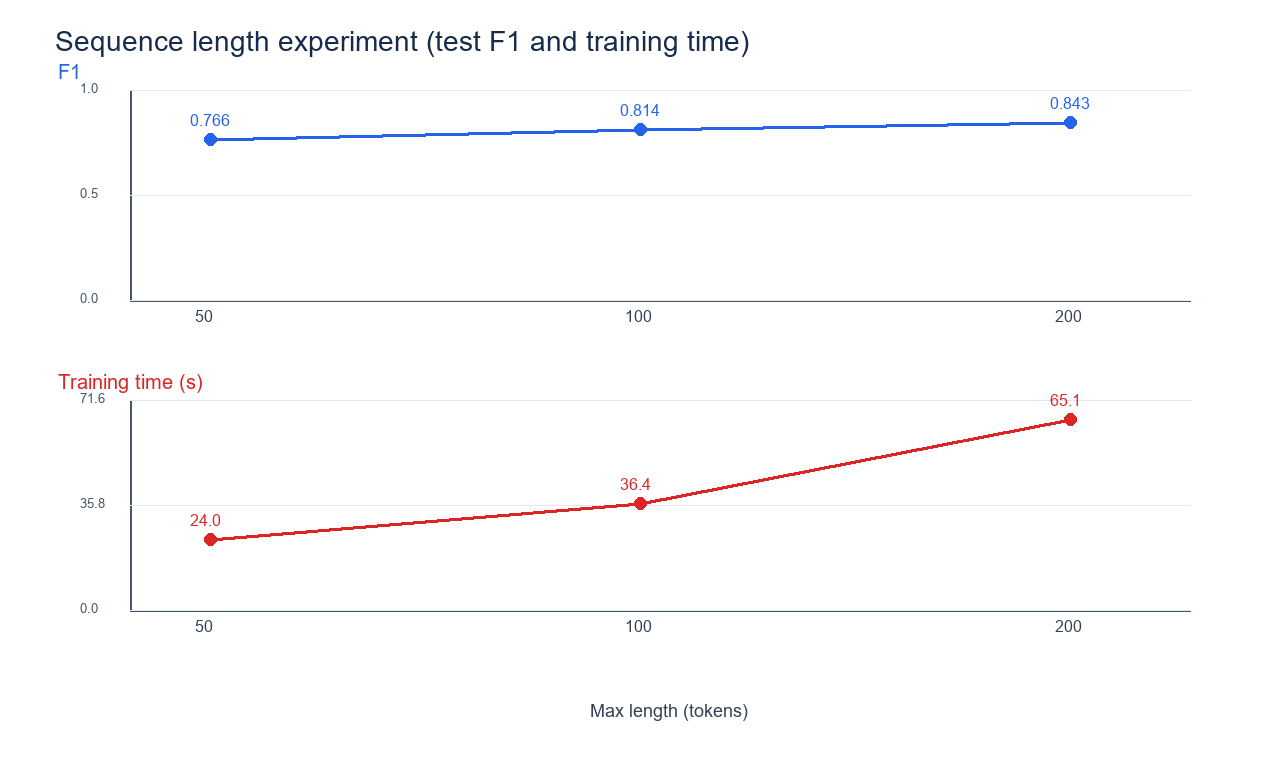

In [20]:
# LAB05_EMBEDDED_FIGURE: sequence_length_experiment.png
from pathlib import Path
from IPython.display import Image, display
_candidates = [Path('Lab05/sequence_length_experiment.png'), Path('sequence_length_experiment.png')]
_image_path = next((p for p in _candidates if p.exists()), None)
if _image_path is None:
    raise FileNotFoundError('sequence_length_experiment.png')
display(Image(filename=str(_image_path)))

## 19. Long-range dependency experiment

In [21]:
long_range_rows = []
if DATA_AVAILABLE:
    for model_type in ("rnn", "lstm", "gru"):
        model = models[(model_type, BASE_MAX_LENGTH)]
        for case_index, case in enumerate(build_long_range_cases()):
            prediction = predict_sentiment(case["sentence"], model, vocabulary, BASE_MAX_LENGTH, DEVICE)
            long_range_rows.append({"experiment": "long_range_dependency", "model": model_type, "split": "probe",
                "max_length": BASE_MAX_LENGTH, "sequence_length": case["sequence_length"],
                "sentiment_word": case["sentiment_word"], "sentiment_word_position": case["sentiment_word_position"],
                "position_region": case["position_region"], "sentence": case["sentence"],
                "was_truncated": prediction["was_truncated"], "prediction": prediction["predicted_label"],
                "probability": prediction["p_positive"], "p_positive": prediction["p_positive"],
                "p_negative": prediction["p_negative"], "sample_id": f"probe-{case_index}", "status": "completed"})
    result_rows.extend(long_range_rows)
    display(pd.DataFrame(long_range_rows).head(12))
    print("Controlled probes are empirical observations; they do not prove vanishing gradients.")
else:
    print("[CHƯA CÓ KẾT QUẢ] Long-range dependency probes require trained models.")

Controlled probes are empirical observations; they do not prove vanishing gradients.


,experiment,model,split,max_length,sequence_length,sentiment_word,sentiment_word_position,position_region,sentence,was_truncated,prediction,probability,p_positive,p_negative,sample_id,status
0,long_range_dependency,rnn,probe,100,50,excellent,5,near_beginning,the scene and story unfold excellent the scene...,False,positive,0.636690,0.636690,0.363310,probe-0,completed
1,long_range_dependency,rnn,probe,100,50,excellent,25,near_middle,the scene and story unfold quietly the scene a...,False,positive,0.636690,0.636690,0.363310,probe-1,completed
2,long_range_dependency,rnn,probe,100,50,excellent,48,near_end,the scene and story unfold quietly the scene a...,False,positive,0.619257,0.619257,0.380743,probe-2,completed
3,long_range_dependency,rnn,probe,100,50,terrible,5,near_beginning,the scene and story unfold terrible the scene ...,False,positive,0.636690,0.636690,0.363310,probe-3,completed
4,long_range_dependency,rnn,probe,100,50,terrible,25,near_middle,the scene and story unfold quietly the scene a...,False,positive,0.636690,0.636690,0.363310,probe-4,completed
5,long_range_dependency,rnn,probe,100,50,terrible,48,near_end,the scene and story unfold quietly the scene a...,False,positive,0.606201,0.606201,0.393799,probe-5,completed
6,long_range_dependency,rnn,probe,100,100,excellent,10,near_beginning,the scene and story unfold quietly the scene a...,False,positive,0.650114,0.650114,0.349886,probe-6,completed
7,long_range_dependency,rnn,probe,100,100,excellent,50,near_middle,the scene and story unfold quietly the scene a...,False,positive,0.650114,0.650114,0.349886,probe-7,completed
8,long_range_dependency,rnn,probe,100,100,excellent,98,near_end,the scene and story unfold quietly the scene a...,False,positive,0.648375,0.648375,0.351625,probe-8,completed
9,long_range_dependency,rnn,probe,100,100,terrible,10,near_beginning,the scene and story unfold quietly the scene a...,False,positive,0.650114,0.650114,0.349886,probe-9,completed


## Analysis — Long-range Dependency

Các input tổng hợp gồm những token đệm lặp lại và một token `excellent` hoặc `terrible`. Bảng hiển thị đoạn trích cục bộ; dấu ba chấm biểu thị các token đệm lặp bị lược bớt. Câu đầy đủ của từng probe được lưu trong `results.csv`. Vị trí là chỉ số token bắt đầu từ 0. Với `max_length=100`, mọi trường hợp dài 200 token đều bị cắt; vị trí 100 và 198 nằm ngoài phần đầu được giữ lại.

| Văn bản (đoạn trích) | Từ mang sắc thái | Vị trí token | Độ dài ban đầu | Bị cắt? | RNN (nhãn; P+/P−) | LSTM (nhãn; P+/P−) | GRU (nhãn; P+/P−) |
|---|---|---:|---:|---|---|---|---|
| the scene and story unfold **excellent** the scene and story unfold … | excellent | 5 (gần đầu) | 50 | No | tích cực (0.6367/0.3633) | tích cực (0.9066/0.0934) | tích cực (0.9786/0.0214) |
| … and story unfold quietly the **excellent** and story unfold quietly the … | excellent | 25 (gần giữa) | 50 | No | tích cực (0.6367/0.3633) | tích cực (0.9067/0.0933) | tích cực (0.9789/0.0211) |
| … scene and story unfold quietly **excellent** scene | excellent | 48 (gần cuối) | 50 | No | tích cực (0.6193/0.3807) | tích cực (0.9170/0.0830) | tích cực (0.9756/0.0244) |
| the scene and story unfold **terrible** the scene and story unfold … | terrible | 5 (gần đầu) | 50 | No | tích cực (0.6367/0.3633) | tích cực (0.9064/0.0936) | tích cực (0.9705/0.0295) |
| … and story unfold quietly the **terrible** and story unfold quietly the … | terrible | 25 (gần giữa) | 50 | No | tích cực (0.6367/0.3633) | tích cực (0.9062/0.0938) | tích cực (0.9715/0.0285) |
| … scene and story unfold quietly **terrible** scene | terrible | 48 (gần cuối) | 50 | No | tích cực (0.6062/0.3938) | tích cực (0.8451/0.1549) | tích cực (0.9174/0.0826) |
| … quietly the scene and story **excellent** quietly the scene and story … | excellent | 10 (gần đầu) | 100 | No | tích cực (0.6501/0.3499) | tích cực (0.9057/0.0943) | tích cực (0.9760/0.0240) |
| … story unfold quietly the scene **excellent** story unfold quietly the scene … | excellent | 50 (gần giữa) | 100 | No | tích cực (0.6501/0.3499) | tích cực (0.9057/0.0943) | tích cực (0.9761/0.0239) |
| … story unfold quietly the scene **excellent** story | excellent | 98 (gần cuối) | 100 | No | tích cực (0.6484/0.3516) | tích cực (0.9174/0.0826) | tích cực (0.9776/0.0224) |
| … quietly the scene and story **terrible** quietly the scene and story … | terrible | 10 (gần đầu) | 100 | No | tích cực (0.6501/0.3499) | tích cực (0.9057/0.0943) | tích cực (0.9754/0.0246) |
| … story unfold quietly the scene **terrible** story unfold quietly the scene … | terrible | 50 (gần giữa) | 100 | No | tích cực (0.6501/0.3499) | tích cực (0.9057/0.0943) | tích cực (0.9751/0.0249) |
| … story unfold quietly the scene **terrible** story | terrible | 98 (gần cuối) | 100 | No | tích cực (0.6351/0.3649) | tích cực (0.8380/0.1620) | tích cực (0.9524/0.0476) |
| … story unfold quietly the scene **excellent** story unfold quietly the scene … | excellent | 20 (gần đầu) | 200 | Yes | tích cực (0.6501/0.3499) | tích cực (0.9057/0.0943) | tích cực (0.9760/0.0240) |
| … quietly the scene and story **excellent** quietly the scene and story … | excellent | 100 (gần giữa) | 200 | Yes | tích cực (0.6501/0.3499) | tích cực (0.9057/0.0943) | tích cực (0.9758/0.0242) |
| … scene and story unfold quietly **excellent** scene | excellent | 198 (gần cuối) | 200 | Yes | tích cực (0.6501/0.3499) | tích cực (0.9057/0.0943) | tích cực (0.9758/0.0242) |
| … story unfold quietly the scene **terrible** story unfold quietly the scene … | terrible | 20 (gần đầu) | 200 | Yes | tích cực (0.6501/0.3499) | tích cực (0.9057/0.0943) | tích cực (0.9755/0.0245) |
| … quietly the scene and story **terrible** quietly the scene and story … | terrible | 100 (gần giữa) | 200 | Yes | tích cực (0.6501/0.3499) | tích cực (0.9057/0.0943) | tích cực (0.9758/0.0242) |
| … scene and story unfold quietly **terrible** scene | terrible | 198 (gần cuối) | 200 | Yes | tích cực (0.6501/0.3499) | tích cực (0.9057/0.0943) | tích cực (0.9758/0.0242) |


Cả ba mô hình dự đoán nhãn tích cực ở 54/54 probe, kể cả input có từ `terrible`. Không có nhãn dự đoán nào đổi khi di chuyển từ mục tiêu giữa đầu/giữa/cuối câu; xác suất vẫn biến thiên. Với chuỗi dài 200 token, truncation loại bỏ từ mục tiêu ở vị trí giữa/cuối, nên các hàng đó không thể kiểm tra ảnh hưởng của từ bị mất lên chuỗi còn lại. Thí nghiệm nhỏ có kiểm soát này không chứng minh cũng không bác bỏ hiện tượng vanishing gradient.

## 20. Evaluation metrics

In [22]:
if DATA_AVAILABLE:
    metric_rows = [row for row in result_rows if row["split"] == "test" and row["experiment"] in {"baseline", "model_comparison", "sequence_length"}]
    display(pd.DataFrame(metric_rows)[["experiment", "model", "max_length", "accuracy", "precision", "recall", "f1", "parameters", "training_time", "epochs"]])
    print("Class mapping: 0 = negative; 1 = positive. Precision/recall/F1 use positive as the positive class.")
else:
    print("[CHƯA CÓ KẾT QUẢ] Classification metrics require completed evaluations.")

Class mapping: 0 = negative; 1 = positive. Precision/recall/F1 use positive as the positive class.


,experiment,model,max_length,accuracy,precision,recall,f1,parameters,training_time,epochs
0,baseline,tfidf_logistic,NaN,0.8958,0.886071,0.9084,0.897097,50001,5.893100,1
1,model_comparison,rnn,100.0,0.5899,0.560834,0.8288,0.668981,1928385,33.707559,3
2,model_comparison,lstm,100.0,0.7583,0.736409,0.8046,0.768996,1953345,38.442315,3
3,model_comparison,gru,100.0,0.7975,0.752418,0.8868,0.814101,1945025,36.419442,3
4,sequence_length,gru,50.0,0.7462,0.710788,0.8302,0.765867,1945025,23.982876,3
5,sequence_length,gru,200.0,0.8399,0.825762,0.8616,0.843300,1945025,65.110962,3
6,sequence_length,gru,100.0,0.7975,0.752418,0.8868,0.814101,1945025,36.419442,3


## 21. Confusion matrix

In [23]:
confusion_matrices = {}
if DATA_AVAILABLE:
    confusion_matrices["TF-IDF + LR"] = baseline_result["test"]["confusion_matrix"]
    for model_type in ("rnn", "lstm", "gru"):
        confusion_matrices[model_type.upper()] = evaluations[(model_type, BASE_MAX_LENGTH, "test")]["confusion_matrix"]
print("CONFUSION_COUNTS_JSON=" + json.dumps({name: matrix.tolist() for name, matrix in confusion_matrices.items()}, sort_keys=True))
CONFUSION_PATH = OUTPUT_DIR / "confusion_matrix.png"
plot_confusion_matrices(confusion_matrices, CONFUSION_PATH)
print({"path": str(CONFUSION_PATH), "class_mapping": {0: "negative", 1: "positive"},
       "cells": "True Negative (TN), False Positive (FP), False Negative (FN), True Positive (TP)"})

CONFUSION_COUNTS_JSON={"GRU": [[3541, 1459], [566, 4434]], "LSTM": [[3560, 1440], [977, 4023]], "RNN": [[1755, 3245], [856, 4144]], "TF-IDF + LR": [[4416, 584], [458, 4542]]}
{'path': 'D:\\Study\\Semester 7\\NLP\\Lab05\\confusion_matrix.png', 'class_mapping': {0: 'negative', 1: 'positive'}, 'cells': 'True Negative (TN), False Positive (FP), False Negative (FN), True Positive (TP)'}


## Analysis — Classification Errors

Quy ước lớp: tiêu cực = 0, tích cực = 1. Ma trận có dạng `[[TN, FP], [FN, TP]]`, tính trên 10.000 bài đánh giá test.

| Mô hình | TP | TN | FP | FN | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|---:|---:|
| TF-IDF + LR | 4.542 | 4.416 | 584 | 458 | 0.8861 | 0.9084 | 0.8971 |
| RNN | 4.144 | 1.755 | 3.245 | 856 | 0.5608 | 0.8288 | 0.6690 |
| LSTM | 4.023 | 3.560 | 1.440 | 977 | 0.7364 | 0.8046 | 0.7690 |
| GRU | 4.434 | 3.541 | 1.459 | 566 | 0.7524 | 0.8868 | 0.8141 |

Ở cả bốn mô hình, False Positive nhiều hơn False Negative (TF-IDF + LR: 584 so với 458; RNN: 3.245 so với 856; LSTM: 1.440 so với 977; GRU: 1.459 so với 566). False Positive là đánh giá tiêu cực bị dự đoán thành tích cực; False Negative là đánh giá tích cực bị bỏ sót. Precision phản ánh mức lẫn mẫu tiêu cực trong các dự đoán tích cực; Recall phản ánh số mẫu tích cực bị bỏ sót; F1 cân bằng Precision và Recall.

### Ma trận nhầm lẫn của các mô hình


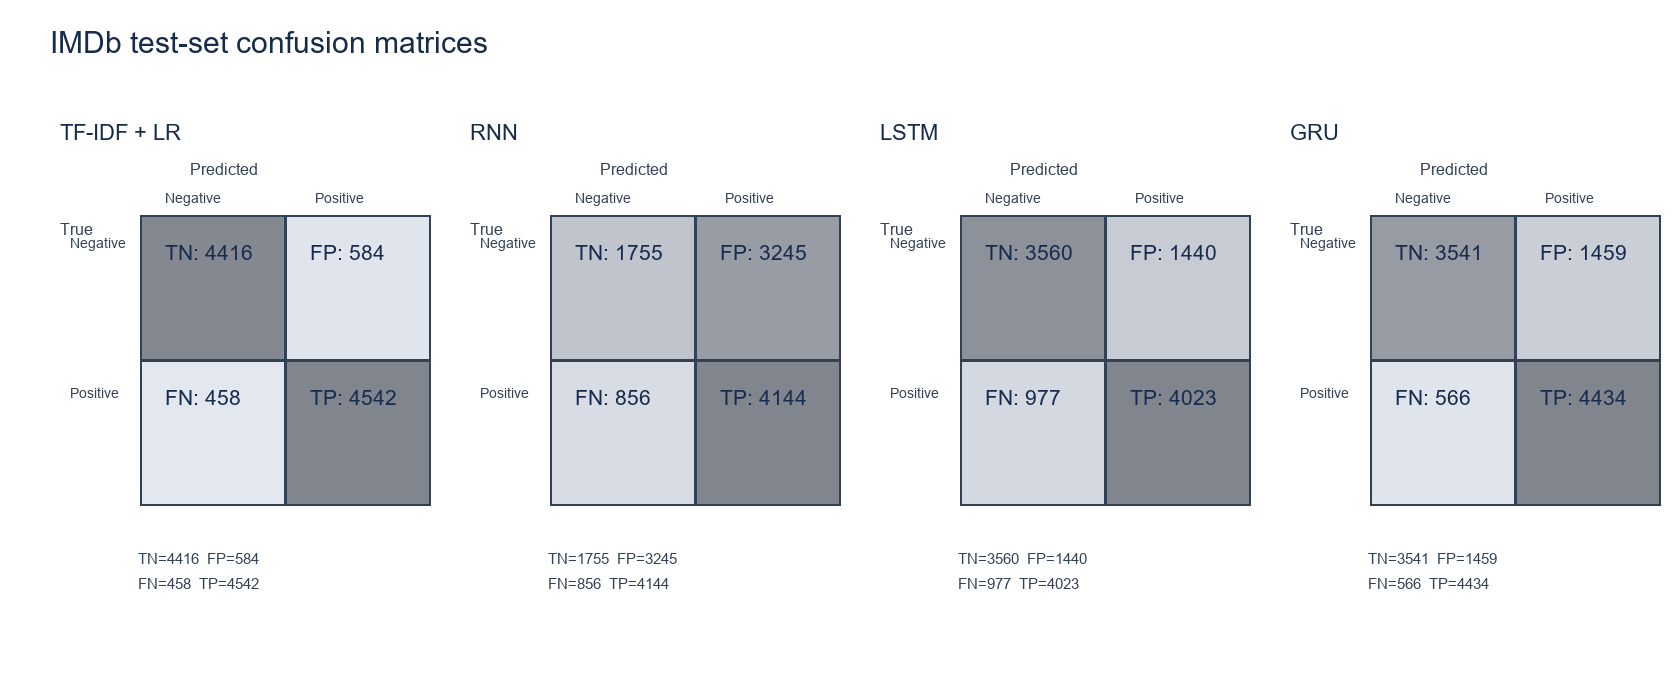

In [24]:
# LAB05_EMBEDDED_FIGURE: confusion_matrix.png
from pathlib import Path
from IPython.display import Image, display
_candidates = [Path('Lab05/confusion_matrix.png'), Path('confusion_matrix.png')]
_image_path = next((p for p in _candidates if p.exists()), None)
if _image_path is None:
    raise FileNotFoundError('confusion_matrix.png')
display(Image(filename=str(_image_path)))

## 22. Learning curves

In [25]:
print("LEARNING_CURVE_DATA_JSON=" + json.dumps({name: {metric: [float(value) for value in values] for metric, values in history.items()} for name, history in histories.items()}, sort_keys=True))
LEARNING_CURVES_PATH = OUTPUT_DIR / "learning_curves.png"
plot_learning_curves(histories, LEARNING_CURVES_PATH)
print(LEARNING_CURVES_PATH)

LEARNING_CURVE_DATA_JSON={"gru_length_100": {"train_loss": [0.6758153751558408, 0.5253732146476091, 0.41411405662479306], "validation_loss": [0.600560371692364, 0.4885575563801445, 0.4419480407768898]}, "gru_length_200": {"train_loss": [0.6407189787793457, 0.48097582584215853, 0.3651416431672488], "validation_loss": [0.554320000443864, 0.4327925424344144, 0.3717378228299531]}, "gru_length_50": {"train_loss": [0.6749448021478562, 0.5542608695660082, 0.46107543643361004], "validation_loss": [0.6141995872080568, 0.5458880851143285, 0.5106938966372718]}, "lstm_length_100": {"train_loss": [0.6797424435723983, 0.6360308347163728, 0.5298963759406836], "validation_loss": [0.647355071446191, 0.594090028330382, 0.5094622494238108]}, "rnn_length_100": {"train_loss": [0.694528696097934, 0.6765133162851207, 0.6570819754489688], "validation_loss": [0.6863811305659985, 0.6746569876728753, 0.689944626348704]}}
D:\Study\Semester 7\NLP\Lab05\learning_curves.png


## Analysis — Learning Curves

Epoch tốt nhất là epoch (đếm từ 1) có validation loss thấp nhất; loss cuối là giá trị ở epoch 3.

| Mô hình / độ dài | Epoch tốt nhất | Validation loss tốt nhất | Training loss cuối | Validation loss cuối |
|---|---:|---:|---:|---:|
| rnn / 100 | 2 | 0.674657 | 0.657082 | 0.689945 |
| lstm / 100 | 3 | 0.509462 | 0.529896 | 0.509462 |
| gru / 50 | 3 | 0.510694 | 0.461075 | 0.510694 |
| gru / 100 | 3 | 0.441948 | 0.414114 | 0.441948 |
| gru / 200 | 3 | 0.371738 | 0.365142 | 0.371738 |

Training loss giảm ở cả năm lần train. Validation loss giảm đến epoch 3 với LSTM và ba cấu hình GRU. Với RNN, validation loss giảm xuống 0.674657 ở epoch 2 rồi tăng lên 0.689945 ở epoch 3, trong khi training loss tiếp tục giảm còn 0.657082; đây là dấu hiệu overfitting quan sát được, bắt đầu sau epoch 2. Bốn đường cong còn lại không có validation loss tăng trở lại trong phạm vi ba epoch.

### Đường cong huấn luyện và validation


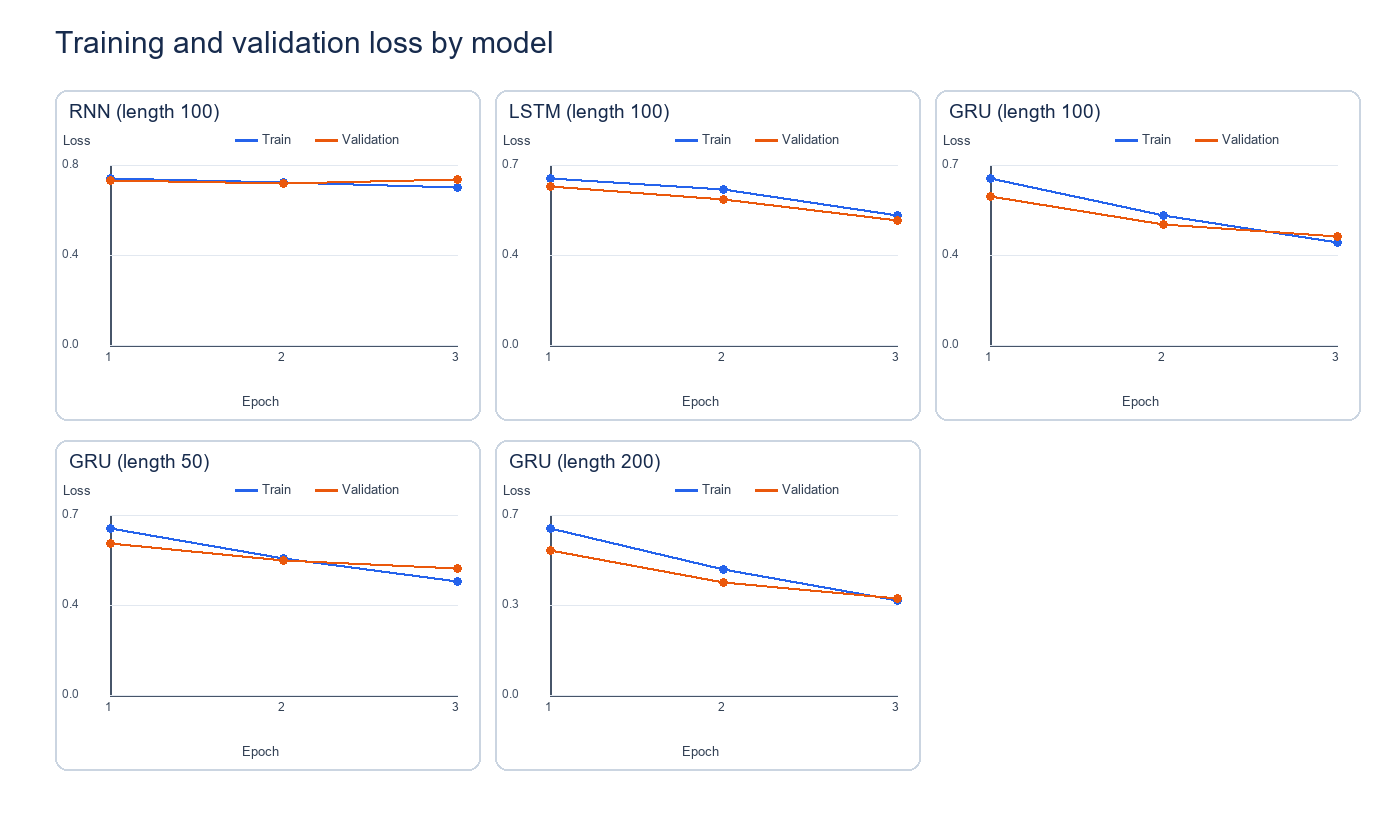

In [26]:
# LAB05_EMBEDDED_FIGURE: learning_curves.png
from pathlib import Path
from IPython.display import Image, display
_candidates = [Path('Lab05/learning_curves.png'), Path('learning_curves.png')]
_image_path = next((p for p in _candidates if p.exists()), None)
if _image_path is None:
    raise FileNotFoundError('learning_curves.png')
display(Image(filename=str(_image_path)))

## 23. Correct/incorrect examples

In [27]:
error_evidence = {"correct": [], "incorrect": []}
if DATA_AVAILABLE:
    error_evidence = analyze_predictions(test_frame, evaluations[("gru", BASE_MAX_LENGTH, "test")], BASE_MAX_LENGTH, count=3)
    save_json(error_evidence, OUTPUT_DIR / "error_analysis_evidence.json")
    print({group: len(rows) for group, rows in error_evidence.items()})
    display(pd.DataFrame(error_evidence["correct"] + error_evidence["incorrect"]))
else:
    print("[CHƯA CÓ KẾT QUẢ] Error analysis requires real held-out predictions.")

{'correct': 11, 'incorrect': 3}


,sample_id,text_preview,true_label,predicted_label,probability_positive,probability_negative,original_token_length,effective_length,was_truncated,context_snippets,review_flags
0,provided_csv:9,If you like original gut wrenching laughter yo...,positive,positive,0.711623,0.288377,34,34,False,[If you like original gut wrenching laughter y...,[]
1,provided_csv:14,This a fantastic movie of three prisoners who ...,positive,positive,0.720880,0.279120,50,50,False,[This a fantastic movie of three prisoners who...,[negation_candidate]
2,provided_csv:15,"Kind of drawn in by the erotic scenes, only to...",negative,negative,0.392519,0.607481,141,100,True,"[Kind of drawn in by the erotic scenes, only t...","[negation_candidate, very_long_or_truncated]"
3,provided_csv:20,After the success of Die Hard and it's sequels...,positive,positive,0.793550,0.206450,316,100,True,[After the success of Die Hard and it's sequel...,"[negation_candidate, very_long_or_truncated]"
4,provided_csv:24,This was the worst movie I saw at WorldFest an...,negative,negative,0.045063,0.954937,154,100,True,[This was the worst movie I saw at WorldFest a...,"[negation_candidate, very_long_or_truncated, s..."
5,provided_csv:26,"""The Cell"" is an exotic masterpiece, a dizzyin...",positive,positive,0.761538,0.238462,576,100,True,"[""The Cell"" is an exotic masterpiece, a dizzyi...","[negation_candidate, very_long_or_truncated]"
6,provided_csv:29,'War movie' is a Hollywood genre that has been...,positive,positive,0.909243,0.090757,631,100,True,['War movie' is a Hollywood genre that has bee...,"[negation_candidate, very_long_or_truncated]"
7,provided_csv:31,"""Ardh Satya"" is one of the finest film ever ma...",positive,positive,0.945417,0.054583,360,100,True,"[""Ardh Satya"" is one of the finest film ever m...",[very_long_or_truncated]
8,provided_csv:39,"After sitting through this pile of dung, my hu...",negative,negative,0.459669,0.540331,265,100,True,"[After sitting through this pile of dung, my h...","[negation_candidate, very_long_or_truncated]"
9,provided_csv:40,It had all the clichés of movies of this type ...,negative,negative,0.449163,0.550837,124,100,True,[It had all the clichés of movies of this type...,"[negation_candidate, very_long_or_truncated]"


## Error Analysis Evidence

Các ví dụ là dự đoán trên tập test giữ lại của GRU (`max_length=100`). Văn bản được trích từ phần xem trước đã lưu. Xác suất trình bày theo P(tích cực)/P(tiêu cực). Ngữ cảnh gần đó được trích dẫn làm bằng chứng; không gán nguyên nhân cho dự đoán.

| Kết quả | Mẫu | Đoạn trích văn bản | Nhãn thật | Nhãn dự đoán | P(tích cực)/P(tiêu cực) | Độ dài ban đầu→thực dùng | Bị cắt? | Ngữ cảnh liên quan |
|---|---|---|---|---|---:|---:|---|---|
| Đúng | provided_csv:9 | If you like original gut wrenching laughter you will like this movie. If you are young or old then you will love this movie, hell even my mom liked it. / Great Camp!!! | tích cực | positive | 0.7116/0.2884 | 34→34 | Không | If you like original gut wrenching laughter you will like this movie. / If you are young or old then you will love this movie, hell even my mom liked it. / Great Camp!!! |
| Đúng | provided_csv:14 | This a fantastic movie of three prisoners who become famous. One of the actors is george clooney and I'm not a fan but this roll is not bad. Another good thing about the movie is the… | tích cực | positive | 0.7209/0.2791 | 50→50 | Không | This a fantastic movie of three prisoners who become famous. / One of the actors is george clooney and I'm not a fan but this roll is not bad. |
| Đúng | provided_csv:15 | Kind of drawn in by the erotic scenes, only to realize this was one of the most amateurish and unbelievable bits of film I've ever seen. Sort of like a high school film project. What was… | tiêu cực | negative | 0.3925/0.6075 | 141→100 | Có | Kind of drawn in by the erotic scenes, only to realize this was one of the most amateurish and unbelievable bits of film I've ever seen. / Sort of like a high school film project. |
| Sai | provided_csv:0 | One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me. / The first thing that struck me… | tích cực | tiêu cực | 0.1552/0.8448 | 314→100 | Có | One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. / They are right, as this is exactly what happened with me. / The first thing that struck me… |
| Sai | provided_csv:28 | This movie was so frustrating. Everything seemed energetic and I was totally prepared to have a good time. I at least thought I'd be able to stand it. But, I was wrong. First, the weird… | tiêu cực | tích cực | 0.7680/0.2320 | 123→100 | Có | This movie was so frustrating. / Everything seemed energetic and I was totally prepared to have a good time. |
| Sai | provided_csv:56 | The Hills Have Eyes II is what you would expect it to be and nothing more. Of course it's not going to be an Oscar nominated film, it's just pure entertainment which you can just lose… | tiêu cực | tích cực | 0.6358/0.3642 | 214→100 | Có | The Hills Have Eyes II is what you would expect it to be and nothing more. / Of course it's not going to be an Oscar nominated film, it's just pure entertainment which you can just lose… |


Các ví dụ cho thấy dự đoán riêng lẻ và trạng thái truncation để sinh viên tự xem xét. Đoạn trích và các cờ không chứng minh phủ định, mỉa mai, truncation hay đặc điểm nào khác đã gây ra dự đoán.

## 24. Sentiment application

In [28]:
application_predictions = []
if DATA_AVAILABLE:
    long_review = ("The acting and cinematography keep the film engaging. " * 35) + "The final act was excellent."
    application_inputs = {
        "short": "I really enjoyed this movie.",
        "long": long_review,
        "negation": "The film was not good, and I would not recommend it.",
        "contrast": "I thought the movie would be terrible, but it was surprisingly good.",
    }
    for name, text in application_inputs.items():
        prediction = predict_sentiment(text, models[("gru", BASE_MAX_LENGTH)], vocabulary, BASE_MAX_LENGTH, DEVICE)
        row = {"experiment": "application", "model": "gru", "split": "inference", "max_length": BASE_MAX_LENGTH,
               "sample_id": name, "text_preview": text[:300], "prediction": prediction["predicted_label"],
               "probability": prediction["p_positive"], "p_positive": prediction["p_positive"],
               "p_negative": prediction["p_negative"], "status": "completed", **prediction}
        application_predictions.append(row)
    result_rows.extend(application_predictions)
    display(pd.DataFrame(application_predictions)[["sample_id", "prediction", "p_positive", "p_negative", "original_token_length", "effective_token_length", "was_truncated"]])
else:
    print("[CHƯA CÓ KẾT QUẢ] Application outputs require a trained model.")

,sample_id,prediction,p_positive,p_negative,original_token_length,effective_token_length,was_truncated
0,short,positive,0.659553,0.340447,5,5,False
1,long,negative,0.063744,0.936256,285,100,True
2,negation,positive,0.615455,0.384545,11,11,False
3,contrast,negative,0.465725,0.534275,12,12,False


## Analysis — Sentiment Prediction Examples

Các dự đoán dùng GRU đã train với `max_length=100`. Phần ngữ cảnh trích từ input được đưa vào, không khẳng định đó là lý do mô hình chọn nhãn.

| Ví dụ | Văn bản | Sentiment dự đoán | P(tích cực)/P(tiêu cực) | Ngữ cảnh trong input | Độ dài token | Bị cắt? |
|---|---|---|---:|---|---:|---|
| Ngắn | “I really enjoyed this movie.” | tích cực | 0.6596/0.3404 | “enjoyed this movie” | 5→5 | Không |
| Dài | (“The acting and cinematography keep the film engaging. ” lặp 35 lần) + “The final act was excellent.” | tiêu cực | 0.0637/0.9363 | Câu lặp về diễn xuất/quay phim; câu về hồi kết nằm phía sau | 285→100 | Có |
| Phủ định | “The film was not good, and I would not recommend it.” | tích cực | 0.6155/0.3845 | “not good”; “not recommend” | 11→11 | Không |
| Tương phản | “I thought the movie would be terrible, but it was surprisingly good.” | tiêu cực | 0.4657/0.5343 | “terrible, but … surprisingly good” | 12→12 | Không |

## 25. Export results.csv

In [29]:
if DATA_AVAILABLE:
    write_results_csv(result_rows, RESULTS_PATH)
else:
    write_results_csv(pending_result_rows("DATASET_REQUIRED"), RESULTS_PATH)
print({"path": str(RESULTS_PATH), "rows": len(result_rows) if DATA_AVAILABLE else len(pending_result_rows()),
       "status": "completed" if DATA_AVAILABLE else "DATASET_REQUIRED"})

{'path': 'D:\\Study\\Semester 7\\NLP\\Lab05\\results.csv', 'rows': 71, 'status': 'completed'}


## 26. Experimental evidence summary

In [30]:
if DATA_AVAILABLE:
    evidence_summary = {"dataset": DATASET_SOURCE, "source_train_samples": dataset_summary["source_train_samples"],
        "source_test_samples": dataset_summary["source_test_samples"], "split_sizes": dataset_summary["split_sizes_after_leakage_check"],
        "vocabulary_size": vocab_size, "length_statistics": dataset_summary["length_statistics"],
        "cross_split_duplicates_after_cleaning": split_cleanup["cross_split_duplicates_after_cleaning"],
        "results_rows": len(result_rows), "status": "completed"}
else:
    evidence_summary = {"dataset": DATASET_ID, "status": "DATASET_REQUIRED", "dataset_error": DATASET_ERROR,
                        "metrics": "[CHƯA CÓ KẾT QUẢ]", "synthetic_training_data_used": False}
print(json.dumps(evidence_summary, ensure_ascii=False, indent=2))

{
  "dataset": "local CSV partitions: D:\\Study\\Semester 7\\NLP\\Lab05\\data",
  "source_train_samples": 40000,
  "source_test_samples": 10000,
  "split_sizes": {
    "train": 31879,
    "validation": 7904,
    "test": 10000
  },
  "vocabulary_size": 30000,
  "length_statistics": {
    "number_of_samples": 50000,
    "minimum_sequence_length": 6,
    "median_sequence_length": 176.0,
    "mean_sequence_length": 234.96742,
    "maximum_sequence_length": 2493,
    "P50": 176.0,
    "P75": 285.25,
    "P90": 458.09999999999854,
    "P95": 599.0,
    "P99": 918.0
  },
  "cross_split_duplicates_after_cleaning": 0,
  "results_rows": 71,
  "status": "completed"
}


## 27. AI assistance statement

In [31]:
ai_assistance_statement = {
    "Tool": "Codex",
    "Purpose": "Code implementation, debugging, training loop support and visualization.",
    "Generated": ["Lab05/rnn_cell.py", "Lab05/sequence_models.py", "Lab05/sequence_classification.ipynb", "Lab05/test_rnn_cell.py", "Lab05/test_sequence_models.py"],
    "Modified": ["Lab05/.gitignore", "Lab05/README.md", "Lab05/sequence_models.py", "Lab05/sequence_classification.ipynb", "Lab05/test_sequence_models.py", "Lab05/results.csv", "Lab05/learning_curves.png", "Lab05/confusion_matrix.png", "Lab05/sequence_length_histogram.png", "Lab05/sequence_length_experiment.png"],
    "Verified": {
        "unit_tests": "19 passed: 2 SimpleRNNCell and 17 sequence, split, padding, model, CSV, and plot checks.",
        "RNN_calculation": "Actual [0.5849798828807288, 0.29131261245159096]; expected [0.584979883, 0.291312612]; torch.nn.RNNCell matched.",
        "notebook": "27/27 code cells executed in a fresh in-process IPython shell with the supplied 50,000-review CSV; training, probes, application predictions, CSV, and plots were generated. This was not a separate Jupyter-kernel Run All."
    },
}
print(json.dumps(ai_assistance_statement, ensure_ascii=False, indent=2))

{
  "Tool": "Codex",
  "Purpose": "Code implementation, debugging, training loop support and visualization.",
  "Generated": [
    "Lab05/rnn_cell.py",
    "Lab05/sequence_models.py",
    "Lab05/sequence_classification.ipynb",
    "Lab05/test_rnn_cell.py",
    "Lab05/test_sequence_models.py"
  ],
  "Modified": [
    "Lab05/.gitignore",
    "Lab05/README.md",
    "Lab05/sequence_models.py",
    "Lab05/sequence_classification.ipynb",
    "Lab05/test_sequence_models.py",
    "Lab05/results.csv",
    "Lab05/learning_curves.png",
    "Lab05/confusion_matrix.png",
    "Lab05/sequence_length_histogram.png",
    "Lab05/sequence_length_experiment.png"
  ],
  "Verified": {
    "unit_tests": "19 passed: 2 SimpleRNNCell and 17 sequence, split, padding, model, CSV, and plot checks.",
    "RNN_calculation": "Actual [0.5849798828807288, 0.29131261245159096]; expected [0.584979883, 0.291312612]; torch.nn.RNNCell matched.",
    "notebook": "27/27 code cells executed in a fresh in-process IPython shell 

## Experimental Summary

- **So sánh mô hình:** TF-IDF + LR đạt test F1 0.8971 trong 5,89 s. Trong nhóm mô hình hồi quy, GRU có test F1 cao nhất (0.8141); RNN train nhanh nhất (33,71 s).
- **Chi phí tính toán:** với GRU, tăng `max_length` từ 50 lên 200 làm thời gian train tăng từ 23,98 lên 65,11 s và bộ nhớ CUDA cấp phát đỉnh tăng từ 112,96 lên 178,09 MB.
- **Độ dài chuỗi:** tỷ lệ token giữ lại tăng từ 21,26% lên 68,35%; tỷ lệ tài liệu train bị cắt giảm từ 97,65% xuống 42,07%; test F1 tăng từ 0.7659 lên 0.8433 trong ba cấu hình đã thử.
- **Overfitting:** validation loss của RNN giảm đến epoch 2 rồi tăng ở epoch 3 trong khi training loss tiếp tục giảm; các đường validation còn lại giảm đến epoch 3.
- **Probe phụ thuộc dài hạn:** cả 54 probe có kiểm soát đều cho nhãn tích cực, kể cả input chứa `terrible`. Trong input 200 token, từ mục tiêu ở vị trí 100/198 bị loại bởi truncation `keep_first` với giới hạn 100. Những probe này không chứng minh cơ chế gradient.
- **Lỗi phân loại:** False Positive nhiều hơn False Negative ở TF-IDF + LR, RNN, LSTM và GRU; các số đếm và ví dụ cụ thể nằm ở trên.
- **Giới hạn:** một seed và ba epoch; chỉ thử độ dài 50/100/200; không có phép ablation thứ tự từ hoặc thí nghiệm 30 token; probe tổng hợp không phải bài đánh giá IMDb. Không tìm thấy nguyên văn dự đoán ban đầu cho bốn chủ đề; không viết thay phần reflection cá nhân.